Run this notebook from the repository root (so that `data/` and `src/` are found). The analysis code lives in `src/eda.py`; the cells below call those functions.

The link to the github repo is https://github.com/jong-nam-ahn/COS424_FinalProject.git

In [1]:
from src import eda   # load the helper file

In [2]:
eda.setup_style()
df = eda.load_data()

## Overview of Overall Dataset

The dataset is a combination of Pitch4KxSpotify and Discogs Ratings. More information on the two datasets can be found in the Milestone 2 proposal.

In [3]:
df[['artist', 'album', 'genre', 'score', 'rating_avg', 'rating_count']].head()

,artist,album,genre,score,rating_avg,rating_count
0,Studio 1,Studio 1,Electronic,8.5,4.42,101.0
1,John Fahey,The Great Santa Barbara Oil Slick,Folk/Country,8.2,4.52,33.0
2,Reigning Sound,Too Much Guitar,Electronic,8.3,4.12,33.0
3,Mac Miller,Swimming,Rap,7.5,4.76,98.0
4,The Essex Green,Essex Green EP,Rock,8.1,4.00,12.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10764 entries, 0 to 10763
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   artist            10764 non-null  str           
 1   album             10764 non-null  str           
 2   reviewauthor      10764 non-null  str           
 3   score             10764 non-null  float64       
 4   releaseyear       10764 non-null  float64       
 5   reviewdate        10764 non-null  datetime64[us]
 6   recordlabel       10756 non-null  str           
 7   genre             10764 non-null  str           
 8   danceability      10764 non-null  float64       
 9   energy            10764 non-null  float64       
 10  key               10764 non-null  float64       
 11  loudness          10764 non-null  float64       
 12  speechiness       10764 non-null  float64       
 13  acousticness      10764 non-null  float64       
 14  instrumentalness  10764 non-null 

**This is a description of the important columns in the dataset:**

| column | meaning | values |
|---|---|---|
| `artist` | artist that released the album |
| `album` | album |
| `reviewauthor` | Pitchfork reviewer that reviewed the album |
| `score` | Pitchfork score of the album given by the reviewer | [0.0, 10.0]
| `releaseyear` | the year that the album released |
| `reviewdate` | the date that the album was reviewed by Pitchfork |
| `recordlabel` | the record label that distributed the album|
| `genre` | the overall genre of the album |
| `danceability` | Spotify audio feature: how suitable a track is for dancing | [0.0, 1.0]
| `energy` | Spotify audio feature: perceptual measure of intensity and activity | [0.0, 1.0]
| `key` | Spotify audio feature: the key the track is in using standard pitch notation| {-1, 11} (-1 = no key detected)
| `loudness` | Spotify audio feature: overall loudness of a track in decibels (dB) | [-60.0, 0.0]
| `speechiness` | Spotify audio feature: presence of spoken words in a track | [0.0, 1.0]
| `acousticness` | Spotify audio feature: confidence measure of whether the track is acoustic | [0.0, 1.0]
| `instrumentalness` | Spotify audio feature: whether a track contains no vocals | [0.0, 1.0]
| `liveness` | Spotify audio feature: the presence of an audience in the recording | [0.0, 1.0]
| `valence` | Spotify audio feature: the musical positiveness conveyed by a track | [0.0, 1.0]
| `tempo` | Spotify audio feature: overall estimated tempo of a track in beats per minute (BPM) | [0.0, 200]
| `date` | the release date of the album on Discogs, used to match the albums |
| `rating_avg` | average Discogs user ratings of the album | [0.0, 5.0]
| `rating_count` | number of Discogs user ratings of the album |
| `have` | number of Discogs users who 'have' the album |
| `want` | number of Discogs users who 'want' the album |
| `match_quality` | score used to match Discogs data with Pitchfork data |

Columns after match quality are values obtained while scraping the Discogs data and matching Discogs data to Pitchfork data.

This is an overall description of the numerical data we will be looking at.

In [5]:
eda.describe_numeric(df)

,releaseyear,score,rating_avg,rating_count,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000
mean,2010.160,7.029,4.174,75.061,0.502,0.607,5.221,-9.277,0.087,0.297,0.300,0.193,0.396,120.527
std,5.317,1.252,0.313,184.586,0.156,0.204,1.595,4.313,0.083,0.261,0.305,0.092,0.181,15.327
min,1998.000,0.000,1.500,10.000,0.060,0.000,0.000,-51.729,0.011,0.000,0.000,0.021,0.000,24.708
25%,2006.000,6.500,4.000,18.000,0.399,0.476,4.350,-11.208,0.041,0.087,0.019,0.134,0.258,111.423
50%,2010.000,7.300,4.200,34.000,0.503,0.631,5.250,-8.427,0.056,0.221,0.181,0.174,0.394,120.481
75%,2015.000,7.800,4.390,73.000,0.612,0.759,6.111,-6.327,0.094,0.457,0.559,0.227,0.524,129.237
max,2019.000,10.000,5.000,9667.000,0.974,0.998,11.000,1.984,0.950,0.995,0.982,0.978,0.969,199.958


## Pitchfork Scores EDA

In this section, we will explore the Pitchfork dataset.

We begin by looking at the Pitchfork score distribution.

#### Finding 1: Pitchfork Score Distribution is Left-Skewed

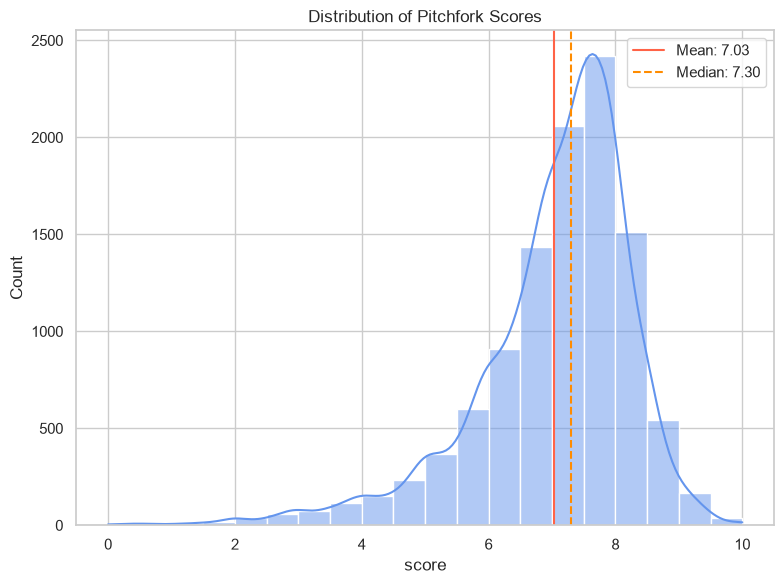

In [6]:
eda.plot_distribution(df['score'], 'Distribution of Pitchfork Scores')

The distribution of the Pitchfork score is left-skewed, with a mean of 7.03 and a median of 7.30.

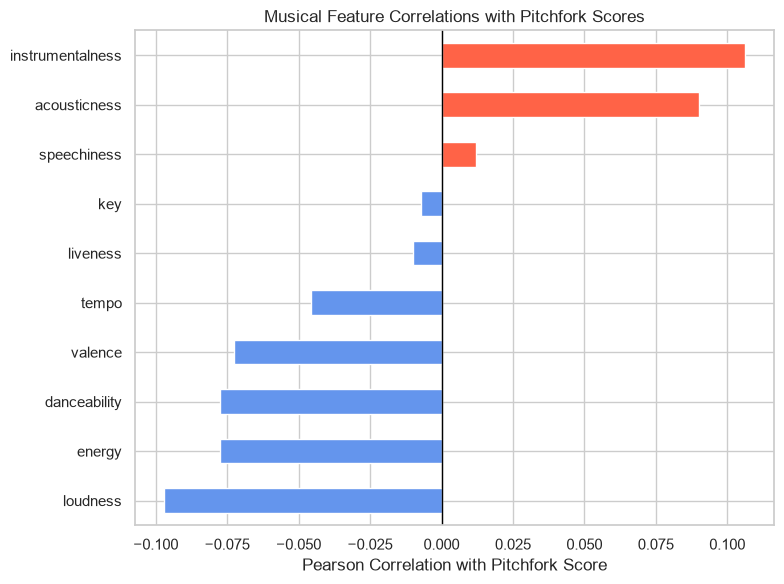

Feature correlations with Pitchfork Score:
loudness           -0.097
energy             -0.077
danceability       -0.077
valence            -0.073
tempo              -0.046
liveness           -0.010
key                -0.007
speechiness         0.012
acousticness        0.090
instrumentalness    0.106
Name: score, dtype: float64


In [7]:
score_correlations = eda.feature_correlations(df, target='score')
eda.plot_feature_correlations(score_correlations)

print('Feature correlations with Pitchfork Score:')
print(score_correlations.round(3))

The Pearson Correlation scores between the Spotify audio features and the Pitchfork scores indicate that there seems to be a very weak relation between them. However, the directionality of correlation differs by audio feature, most of them being negative. 

### Genre Specific Data Analysis

In this section, we explore the Pitchfork scores based on the genre of the album.

#### Finding 2: Jazz has the highest median score; Electronic has the lowest

In [8]:
genre_summary = eda.summarize(df, by='genre', sort_by='mean')

In [9]:
genre_summary

,mean,std,min,median,max,count
genre,,,,,,
Jazz,7.409,1.117,3.0,7.6,10.0,144
Experimental,7.402,1.058,0.3,7.6,10.0,987
Global,7.336,1.041,2.2,7.6,9.0,81
Folk/Country,7.290,1.048,2.3,7.5,10.0,403
Metal,7.101,1.196,0.8,7.4,9.0,569
Rap,7.053,1.298,1.6,7.3,10.0,674
Pop/R&B,7.019,1.108,2.0,7.2,10.0,653
Unknown,6.989,1.122,0.4,7.2,9.7,627
Rock,6.951,1.315,0.0,7.2,10.0,4042


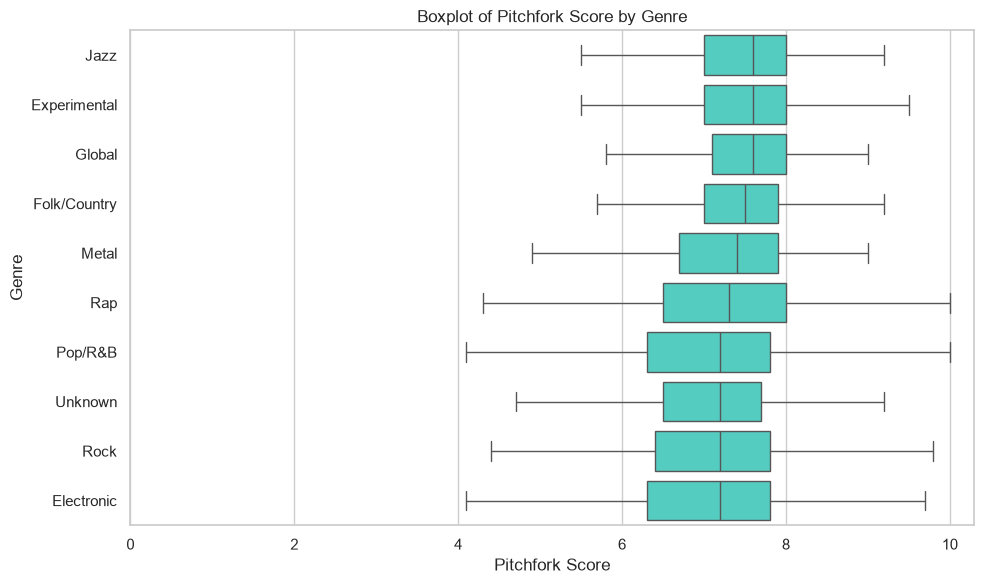

In [10]:
eda.plot_box_by(df, value='score', group='genre',
                order=genre_summary.sort_values('median', ascending=False).index,
                title='Boxplot of Pitchfork Score by Genre',
                xlabel='Pitchfork Score', ylabel='Genre', color='turquoise')

The boxplot shows that the distribution of the Pitchfork scores differs between different genres. The median score of Jazz, Experimental, and Global music are about 0.5 points greater than Pop, Unknown, Rock, and Electronic music. Furthermore, the spreads of Pop and Rap are very large compared to Global and Folk music.

### Review Date Specific Analysis

Next, we explore the Pitchfork scores based on the year that the review was released.

#### Finding 3: Pitchfork Critics Review Albums Fast

In [11]:
eda.count_late_reviews(df, max_gap_years=1)

13

There are only 13 reviews that are retroactive, where the review year is more than one year after the release year. This shows that almost all of the albums were reviewed around the time they were released.

In [12]:
review_year = df['reviewdate'].dt.year
rdate_summary = eda.summarize(df, by=review_year)

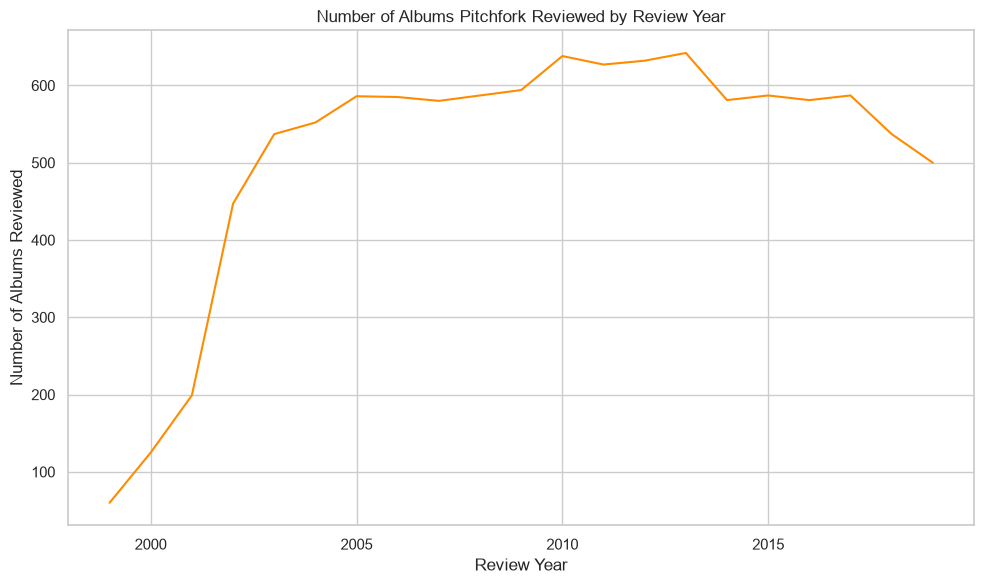

In [13]:
eda.plot_reviews_per_year(rdate_summary)

This graph shows the number of albums Pitchfork reviewed per year, starting from 1999. From 1999 to 2002, the number of albums reviewed per year increased dramatically. From 2003 to 2019, the number of albums reviewed fluctuates slightly, but stayed above 500 reviews per year.

#### Finding 4: There are No Clear Signs of Score Inflation

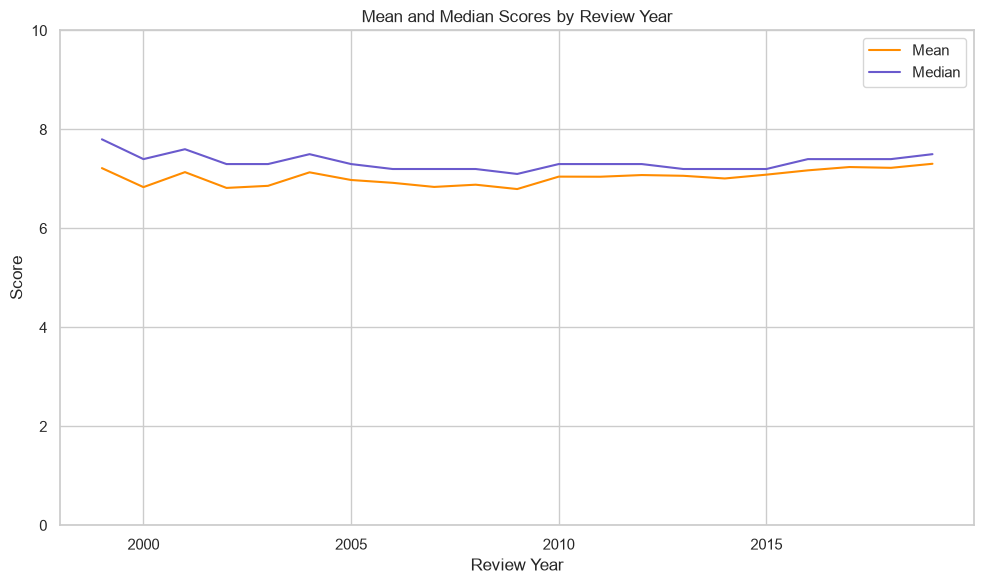

In [14]:
eda.plot_mean_median_per_year(rdate_summary)

This graph shows that the mean and median Pitchfork scores did not vary much over the years. However, it looks like the scores are less left-skewed as time goes on. In the early 2000s, the difference between the mean and median is fairly large, with mean being much lower than the median. In 2019, the difference between them is much smaller.

In [15]:
df = eda.add_review_era(df)   # adds years_bin: 1999-2004, 2005-2009, 2010-2014, 2015-2019

In [16]:
rdate_bin_summary = eda.summarize(df, by='years_bin')

In [17]:
rdate_bin_summary

,mean,std,min,median,max,count
years_bin,,,,,,
1999-2004,6.967,1.616,0.0,7.4,10.0,1920
2005-2009,6.883,1.371,0.0,7.2,10.0,2932
2010-2014,7.049,1.093,1.0,7.3,10.0,3120
2015-2019,7.202,0.940,1.6,7.4,10.0,2792


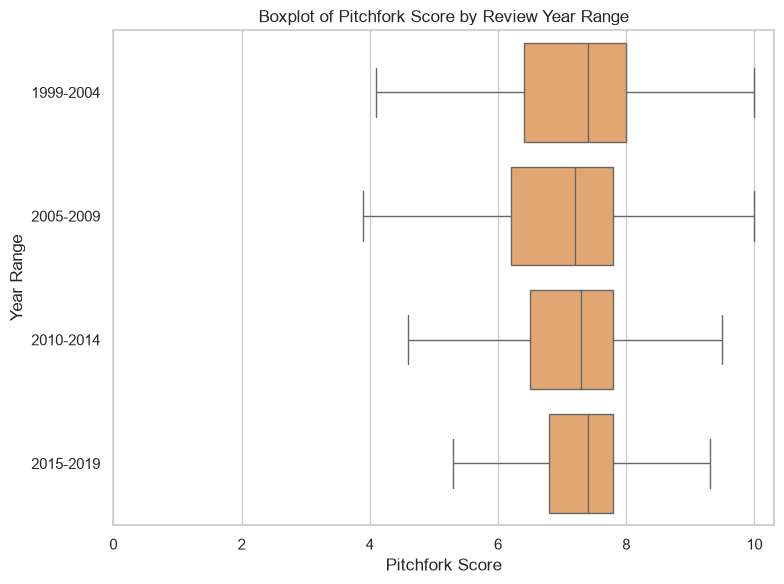

In [18]:
eda.plot_box_by(df, value='score', group='years_bin', order=rdate_bin_summary.index,
                title='Boxplot of Pitchfork Score by Review Year Range',
                xlabel='Pitchfork Score', ylabel='Year Range', color='sandybrown', figsize=(8, 6))

Here we group years into year ranges of around half a decade to not overwhelm the comparisons. The trend of tighter distribution as discovered earlier is much more apparent here, with the width of the boxplots noticeably getting shorter. Additionally, there seems to be a small trend of median scores improving from 2005 to 2019.

### Pitchfork Critic Specific Analysis

Next, we will explore Pitchfork scores based on the reviewers.

#### Finding 5: A Small Group of Critics Dominate Reviews

In [19]:
reviewer_summary = eda.summarize(df, by='reviewauthor', sort_by='count')
reviewer_summary.head(15)

,mean,std,min,median,max,count
reviewauthor,,,,,,
Ian Cohen,6.482,1.488,0.2,6.6,9.3,462
Stephen M. Deusner,6.796,1.351,2.1,7.2,9.6,333
Joe Tangari,7.317,0.846,3.5,7.5,8.9,331
Stuart Berman,7.110,0.966,1.0,7.3,9.2,324
Mark Richardson,7.562,1.190,2.5,7.8,10.0,324
Brian Howe,7.121,0.895,2.8,7.4,9.0,260
Philip Sherburne,7.476,0.734,4.0,7.6,9.1,245
Marc Hogan,6.583,1.537,1.2,6.8,9.2,236
Nate Patrin,7.048,1.149,2.8,7.3,9.2,197


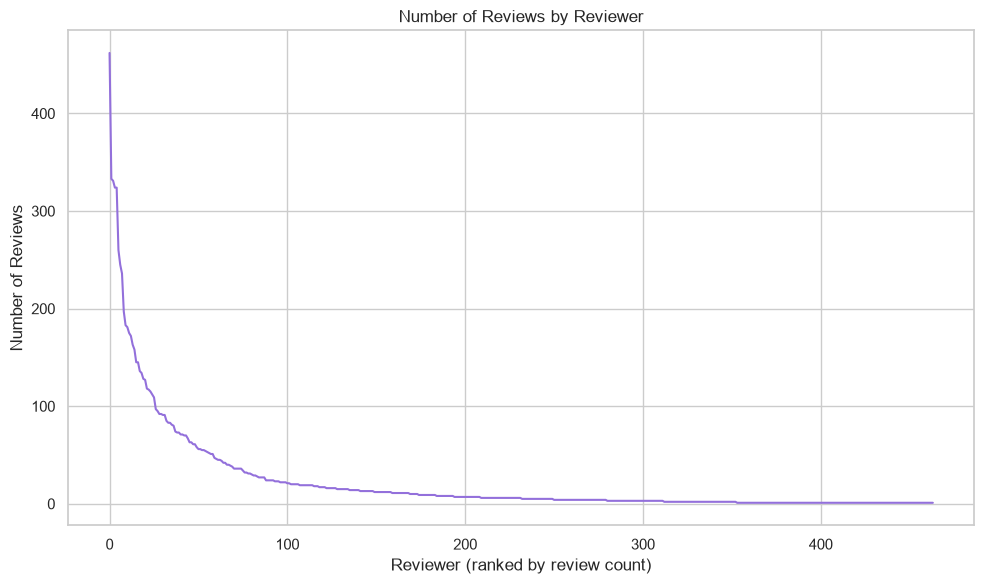

In [20]:
eda.plot_reviews_per_reviewer(reviewer_summary)

This log curve shows that a few reviewers account for a large number of the reviews, with most reviewers only writing a few reviews.

#### Finding 6: Critics Exhibit Different Scoring Tendencies

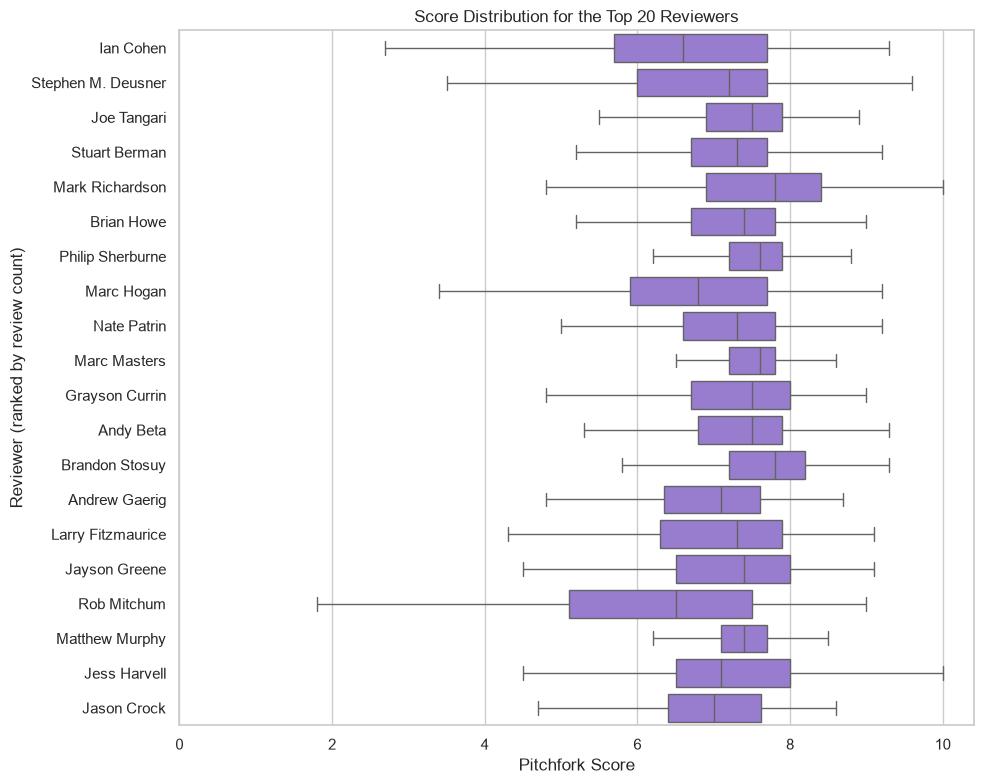

In [21]:
top20_reviewers = reviewer_summary.head(20).index

eda.plot_box_by(df[df['reviewauthor'].isin(top20_reviewers)], value='score', group='reviewauthor',
                order=top20_reviewers, title='Score Distribution for the Top 20 Reviewers',
                xlabel='Pitchfork Score', ylabel='Reviewer (ranked by review count)',
                color='mediumpurple', figsize=(10, 8))

This plot shows the score distributions given by the top 20 reviewers, each having more than 100 reviews. The distributions vary considerably. There's Joe Tangari and Matthew Murphy with very small distributions, and then there's Ian Cohan and Rob Mitchum with very wide distributions.

## EDA Discogs Ratings

In this section, we will explore the Discogs data that we scraped.

We begin by looking at the overall Discogs rating statistics. **In Discogs, scores are rated from 0 to 5.** We multiplied scores by 2 for a more interpretable comparison with Pitchfork scores. 

#### Finding 7: The Median Album is Rated Higher by the Public

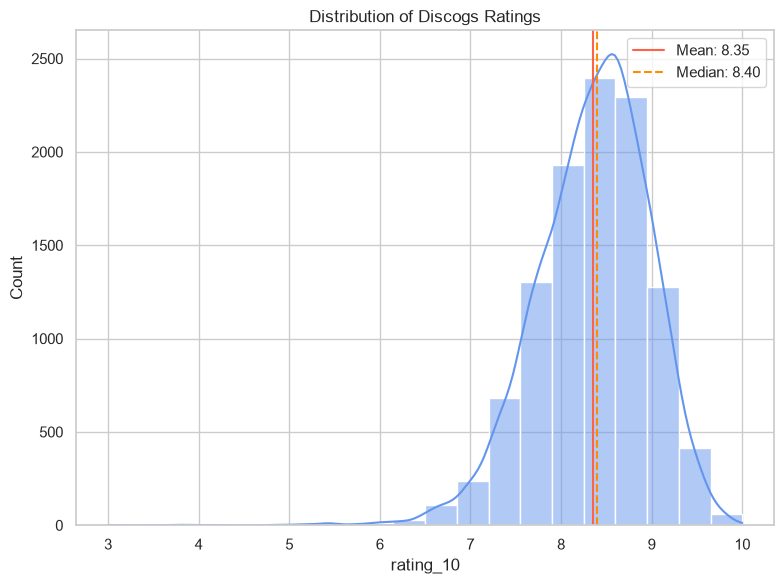

In [22]:
eda.plot_distribution(df['rating_10'], 'Distribution of Discogs Ratings')

We multiplied the Discogs rating averages by 2, since it is on a 0-5 scale, to make it comparable to the Pitchfork score of 0-10 scale. The distribution of average Discogs ratings is slightly left-skewed, with a mean of 8.35, a tiny bit lower than the median of 8.40. The Discogs ratings are considerably more normally distributed than the Pitchfork scores.

### Bin by Rating_count

Next, we will explore Discogs ratings based on the rating counts.

In [23]:
df['rating_count'].max()

np.float64(9667.0)

#### Finding 8: Number of Reviews is Right Skewed

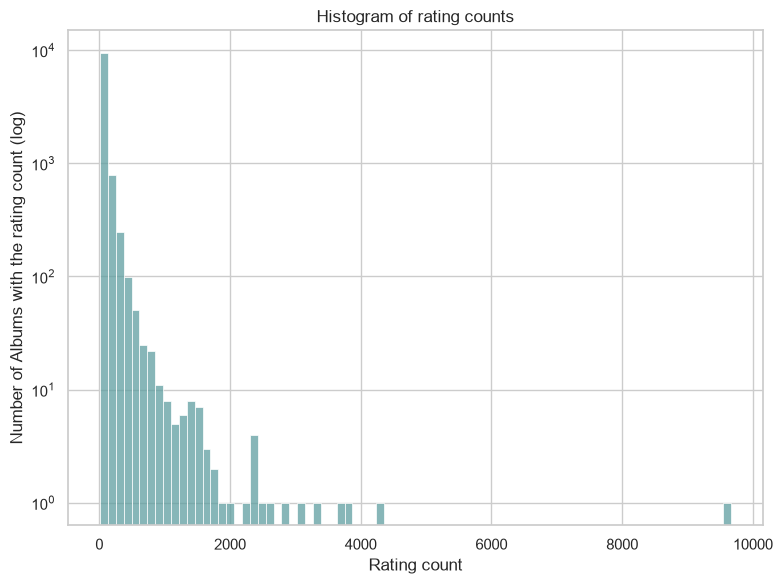

In [24]:
eda.plot_rating_count_hist(df)

The rating count of the albums also follows a long-tailed distribution, with most albums having very low rating counts and a few extremely popular outlier albums having much higher rating counts.

In [25]:
bins = eda.add_count_bins(df, q=5)   # adds counts_bin (0 = fewest ratings); returns the bin edges
bins

array([  10. ,   16. ,   26.2,   45. ,   88. , 9667. ])

In [26]:
bins_summary = eda.summarize(df, by='counts_bin', value='rating_10')
bins_summary

,mean,std,min,median,max,count
counts_bin,,,,,,
0,8.186,0.752,3.00,8.20,10.00,2207
1,8.292,0.630,4.82,8.34,10.00,2099
2,8.337,0.599,4.12,8.38,9.86,2182
3,8.402,0.541,6.20,8.44,9.82,2129
4,8.529,0.521,6.00,8.60,9.78,2147


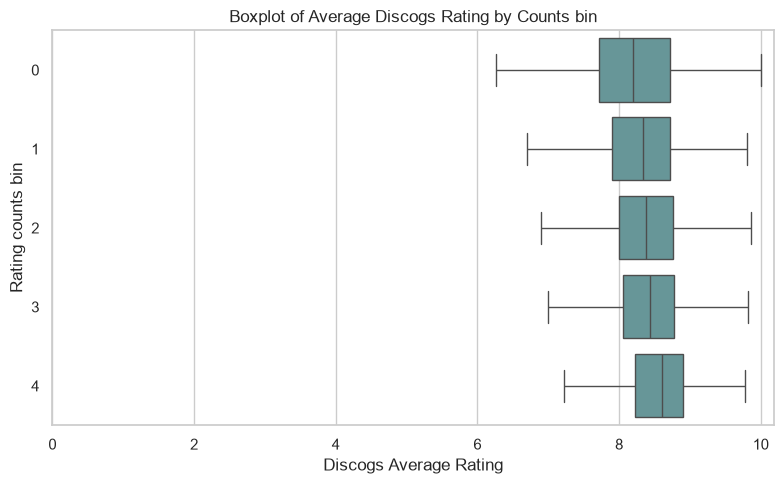

In [27]:
eda.plot_box_by(df, value='rating_10', group='counts_bin', order=bins_summary.index,
                title='Boxplot of Average Discogs Rating by Counts bin',
                xlabel='Discogs Average Rating', ylabel='Rating counts bin',
                color='cadetblue', figsize=(8, 5))

We divide the ratings into 5 equally sized bins: \
bin 0: 10-16 rating counts,\
bin 1: 17-26 rating counts, \
bin 2: 27-45 rating counts, \
bin 3: 46-88 rating counts, \
bin 4: 89-9667 rating counts.

The rating distributions get tighter as the number of reviews go up and the median rating also shifts right, toward higher ratings.

## Understanding Spotify Audio Features: UMAP & PCA

We also conducted a quick UMAP to visualize the clustering of the album genre based on the Spotify audio features.

#### Finding 9: Albums of the Same Genre Cluster Together

In [28]:
# Standardize the 10 audio features and embed albums from the 5 largest genres in 2-D
embedding, umap_genres = eda.umap_embedding(df, n_genres=5)

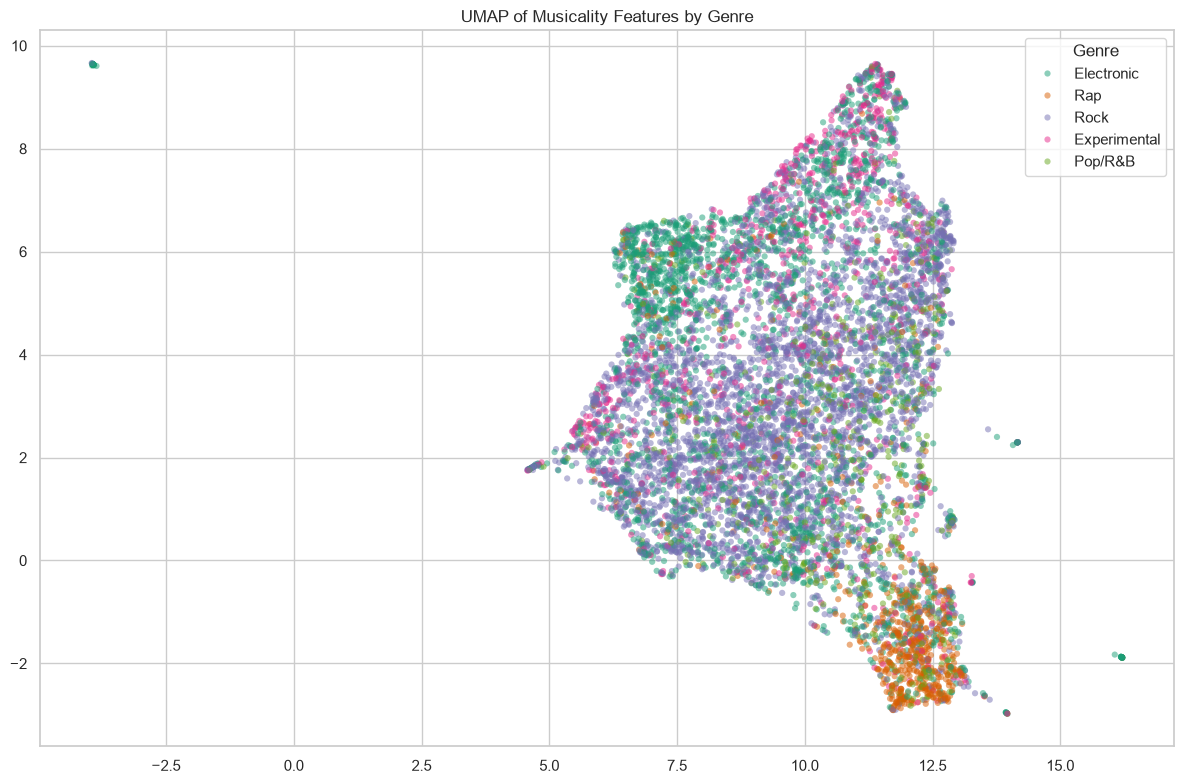

In [29]:
eda.plot_umap(embedding, umap_genres)

Due to the number of genres and data points, we chose to only look at the top 5 genres instead of all 10 in the dataset. Overall, it looks like some genres are more clustered, specifically Rap, whereas Rock does not show strong signs of clustering.

#### Finding 10: Audio Features Overlap Only Partially

Although UMAP is a great visual aid, we wish to understand more about the audio features. Therefore, we check how many independent dimensions they contain through principal component analysis (PCA).

In [30]:
pca = eda.fit_pca(df)
eda.pca_variance_table(pca)

,explained,cumulative
PC1,0.365,0.365
PC2,0.180,0.545
PC3,0.139,0.684
PC4,0.090,0.773
PC5,0.080,0.853
PC6,0.066,0.919
PC7,0.039,0.958
PC8,0.031,0.989
PC9,0.011,1.000


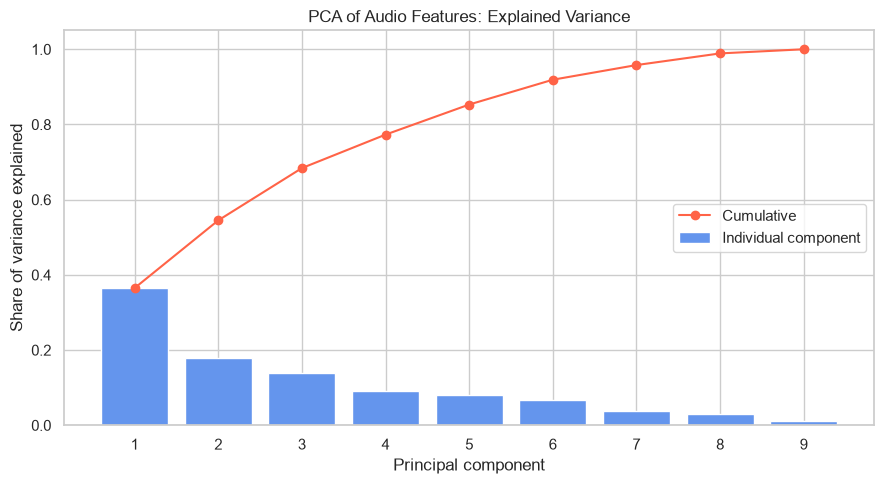

In [31]:
eda.plot_pca_variance(pca)

If the audio features were uncorrelated, each principal component (PC) would account for approximately 11% of the total variance. We observe some feature overlap considering that the first PC explains 36.5%. However, beyond the first component, the variance is spread out, and we need 5 of the 9 components to reach 80% of explainability. Replacing the audio features with select PCs would therefore discard a substantial part of the information. Therefore, when we later run a regression, it is safer to use all audio features then to replace them with PCs.

## Preliminary Findings

#### Finding 11: Across All Genres, Discogs Ratings are Higher

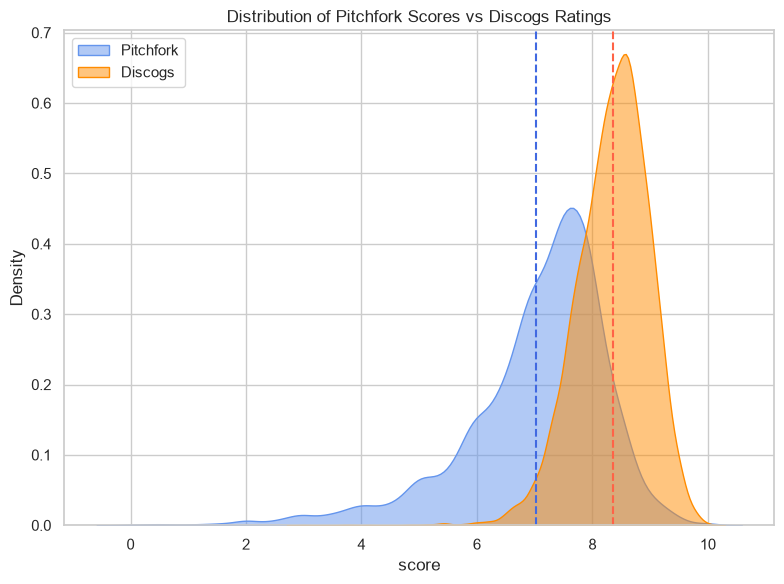

In [32]:
eda.plot_pitchfork_vs_discogs(df)

We overlap the score distribution of Pitchfork and Discogs. We observe that Pitchfork scores are more spread out and left skewed while Discogs scores are more concentrated and are higher.

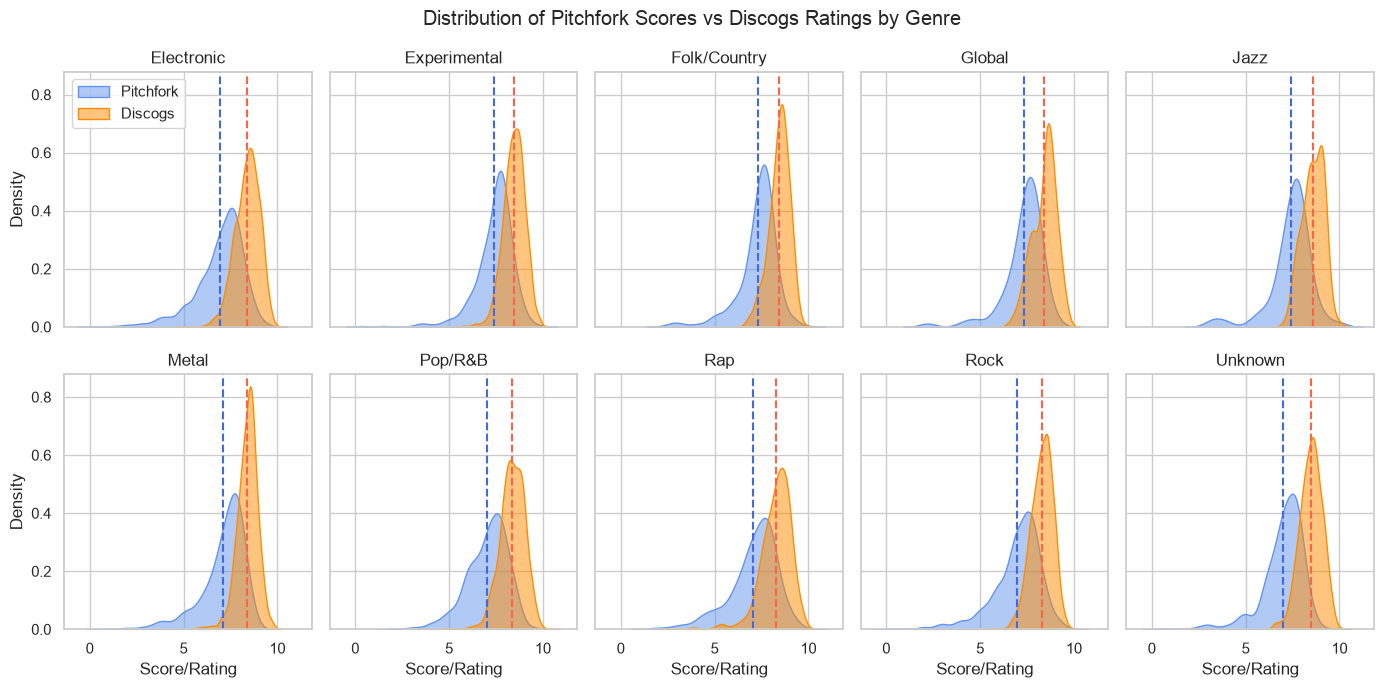

In [33]:
eda.plot_pitchfork_vs_discogs_by_genre(df)

The findings above are consistent across all genres. The concentration of Discogs scores seems to be most prominent for Metal. In the case of Pitchfork, the spread seems to look more consistent relative to Discogs'.

#### Finding 12: Critics and the Public Disagree on the Ranking of Albums

In [34]:
agreement = eda.rank_agreement(df)
agreement

n_albums    10764.000
spearman        0.225
ci_lo           0.208
ci_hi           0.243
dtype: float64

While Discogs users rate albums higher, the ranking of albums might be similar to that of Pitchfork reviewers. We measure how similar the orderings of albums are using Spearman rank correlation. The low spearman correlation indicates that the albums favored by critics are largely different of that of the public. To check how stable the estimate is, we recompute it on 1,000 bootstrap resamples, with the confidence interval range shown above.

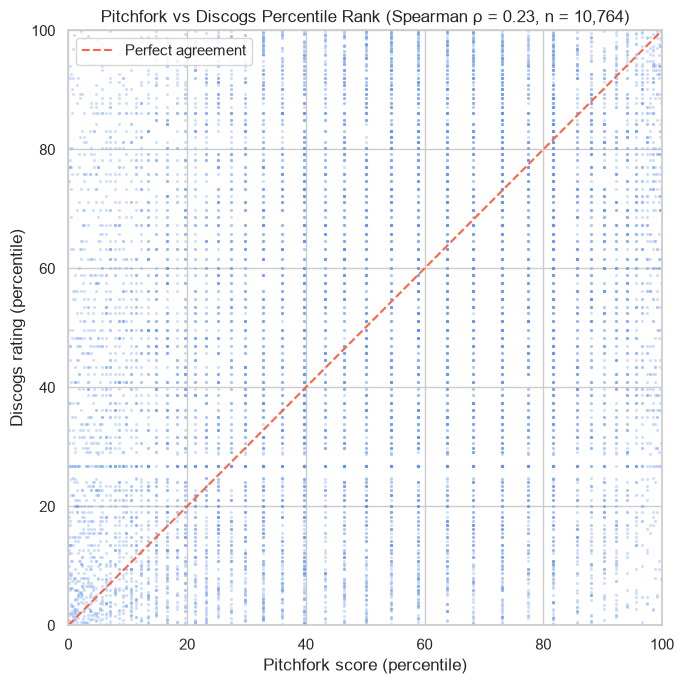

In [35]:
eda.plot_percentile_scatter(df)

If the two sources agreed on the ranking of albums, points would sit along the diagonal line. Instead, the points fill the square almost entirely.